## Caricamento e preparazione dei dati

Import librerie di utility

In [1]:
%reset -f

import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

import training e test set con relative etichette:


*   x = vettore di immagini
*   y = vettore delle rispettive etichette



In [2]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

%whos

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Variable   Type               Data/Info
---------------------------------------
keras      KerasLazyLoader    <KerasLazyLoader>
mnist      module             <module 'keras.api.datase<...>asets/mnist/__init__.py'>
np         module             <module 'numpy' from '/us<...>kages/numpy/__init__.py'>
plt        module             <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
x_test     ndarray            10000x28x28: 7840000 elems, type `uint8`, 7840000 bytes (7.476806640625 Mb)
x_train    ndarray            60000x28x28: 47040000 elems, type `uint8`, 47040000 bytes (44.86083984375 Mb)
y_test     ndarray            10000: 10000 elems, type `uint8`, 10000 bytes
y_train    ndarray            60000: 60000 elems, type `uint8`, 60000 bytes


Estraggo il validation dal training set. Poichè le immagini sono ordinate posso prendere un immagine di validation ogni 12 di training.
Devo poi cancellare le immagini che ho copiato dal training.

In [3]:
x_val = x_train[::12]
y_val = y_train[::12]

#cancello nella dimensione 0, le immagini da x_train con indice da 0 a
#grandezza_train con passo 12
x_train = np.delete(x_train, np.arange(0, x_train.shape[0], 12), 0)
y_train = np.delete(y_train, np.arange(0, y_train.shape[0], 12), 0)

%whos

Variable   Type               Data/Info
---------------------------------------
keras      KerasLazyLoader    <KerasLazyLoader>
mnist      module             <module 'keras.api.datase<...>asets/mnist/__init__.py'>
np         module             <module 'numpy' from '/us<...>kages/numpy/__init__.py'>
plt        module             <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
x_test     ndarray            10000x28x28: 7840000 elems, type `uint8`, 7840000 bytes (7.476806640625 Mb)
x_train    ndarray            55000x28x28: 43120000 elems, type `uint8`, 43120000 bytes (41.1224365234375 Mb)
x_val      ndarray            5000x28x28: 3920000 elems, type `uint8`, 3920000 bytes (3.7384033203125 Mb)
y_test     ndarray            10000: 10000 elems, type `uint8`, 10000 bytes
y_train    ndarray            55000: 55000 elems, type `uint8`, 55000 bytes
y_val      ndarray            5000: 5000 elems, type `uint8`, 5000 bytes


Preparazione dei dati per mandarli in input alla rete. Trasformo in 4 dimensioni:


*   indice immagine dataset
*   riga
*   colonna
*   banda

Infine trasformo in 32 bit e normalizzo

In [4]:
img_rows = 28; img_cols = 28; img_channels = 1;
# reshape nel formato Channels-Last
x_train = np.reshape(x_train, (55000,img_rows,img_cols,img_channels))
x_val = np.reshape(x_val , ( 5000,img_rows,img_cols,img_channels))
x_test = np.reshape(x_test , (10000,img_rows,img_cols,img_channels))

# conversione a float e normalizazione
x_train = np.float32(x_train) / 255
x_val = np.float32(x_val) / 255
x_test = np.float32(x_test) / 255

%whos

Variable       Type               Data/Info
-------------------------------------------
img_channels   int                1
img_cols       int                28
img_rows       int                28
keras          KerasLazyLoader    <KerasLazyLoader>
mnist          module             <module 'keras.api.datase<...>asets/mnist/__init__.py'>
np             module             <module 'numpy' from '/us<...>kages/numpy/__init__.py'>
plt            module             <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
x_test         ndarray            10000x28x28x1: 7840000 elems, type `float32`, 31360000 bytes (29.9072265625 Mb)
x_train        ndarray            55000x28x28x1: 43120000 elems, type `float32`, 172480000 bytes (164.48974609375 Mb)
x_val          ndarray            5000x28x28x1: 3920000 elems, type `float32`, 15680000 bytes (14.95361328125 Mb)
y_test         ndarray            10000: 10000 elems, type `uint8`, 10000 bytes
y_train        ndarray            55000: 55000 elems, 

Trasformo le etichette nel formato One-Hot. Esempio con 10 classi:

*   0 = 1000000000
*   4 = 0000100000
*   7 = 0000000100
*   ecc...



In [5]:
from tensorflow.keras.utils import to_categorical

num_classes = 10

# conversione delle etichette nel formato one-hot
y_train = to_categorical(y_train, num_classes)
y_val = to_categorical(y_val , num_classes)
y_test = to_categorical(y_test , num_classes)

%whos


Variable         Type               Data/Info
---------------------------------------------
img_channels     int                1
img_cols         int                28
img_rows         int                28
keras            KerasLazyLoader    <KerasLazyLoader>
mnist            module             <module 'keras.api.datase<...>asets/mnist/__init__.py'>
np               module             <module 'numpy' from '/us<...>kages/numpy/__init__.py'>
num_classes      int                10
plt              module             <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
to_categorical   function           <function to_categorical at 0x78e4f41c85e0>
x_test           ndarray            10000x28x28x1: 7840000 elems, type `float32`, 31360000 bytes (29.9072265625 Mb)
x_train          ndarray            55000x28x28x1: 43120000 elems, type `float32`, 172480000 bytes (164.48974609375 Mb)
x_val            ndarray            5000x28x28x1: 3920000 elems, type `float32`, 15680000 bytes (14.9536132

## Definizione dell'architettura della rete neurale

Definisco l'architettura della rete neurale. Con la funzione sequential creo un modello vuoto sequenziale che posso popolare con degli strati.

In [6]:
from tensorflow import keras

lenet = keras.models.Sequential()

Definisco i layer per estrarre le features

N.B. solo per il primo livello indichiaimo anche la dimensione dell'ingresso.
Gli strati sono:


*   Layer convoluzionale 2D
*   Layer di Max-Pooling
*   Layer convoluzionale 2D
*   Layer di Max-Pooling



In [7]:
from tensorflow.keras import layers

lenet.add(layers.Conv2D(6, (5, 5), padding='same', activation='relu',
          input_shape=(img_rows,img_cols,img_channels)))

lenet.add(layers.MaxPooling2D((2, 2) ))

lenet.add(layers.Conv2D(16, (5, 5), padding="valid", activation='relu'))

lenet.add(layers.MaxPooling2D((2, 2) ))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Converto l'immagine in un vettore e definisco i 3 layer fully-connected per la classificazione

In [8]:
lenet.add(layers.Flatten())

lenet.add(layers.Dense(120, activation='relu'))
lenet.add(layers.Dense(84, activation='relu'))
lenet.add(layers.Dense(num_classes, activation='softmax'))

Recap architettura

In [9]:
lenet.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

## Addestramento della rete

Definisco tramite il metodo compile la loss function, lo Stochastic Gradient
Descent come algoritmo di ottimizzazione, il learning rate e la metrica da
ottimizzare

In [10]:
lenet.compile(loss = keras.losses.categorical_crossentropy,
              optimizer = keras.optimizers.SGD(learning_rate=0.01),
              metrics = ['accuracy'])


Eseguo il training tramite il metodo fit. Input:
 le immagini di testPossiamo guardare l'andamento dell'addetsramento,

*   Immagini di test
*   Dimensione batch per il testing
*   Numero di epoche
*   Dati di validazione per monitorare l'accuracy

Il parametro verbose permette di mostrare la barra progressiva di addestramento

In [11]:
lenet.fit(x_train, y_train, batch_size=200, epochs=10,
          validation_data=(x_val, y_val), verbose=True)


Epoch 1/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.1745 - loss: 2.2633 - val_accuracy: 0.6400 - val_loss: 1.5155
Epoch 2/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7823 - loss: 0.8908 - val_accuracy: 0.8780 - val_loss: 0.4118
Epoch 3/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9085 - loss: 0.3108 - val_accuracy: 0.8946 - val_loss: 0.3406
Epoch 4/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9276 - loss: 0.2373 - val_accuracy: 0.9096 - val_loss: 0.2848
Epoch 5/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9403 - loss: 0.1980 - val_accuracy: 0.9272 - val_loss: 0.2415
Epoch 6/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9495 - loss: 0.1678 - val_accuracy: 0.9360 - val_loss: 0.2200
Epoch 7/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9556 - loss: 0.1472 - val_accuracy: 0.9386 - val_loss: 0.1968
Epoch 8/10
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9615 - loss: 0.1278 - val_accuracy: 0.

## Analisi delle prestazioni

Testiamo la rete su una singola immagine

N.B. la label è nel formato one-hot. Sfrutto np.argmax per estrarla

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
vettore delle probabilità predette: [[8.3552840e-07 9.9878258e-01 1.2525812e-05 2.1733039e-04 4.6736473e-05
  5.5326167e-05 3.1287695e-06 2.3172455e-04 4.9342675e-04 1.5648839e-04]]


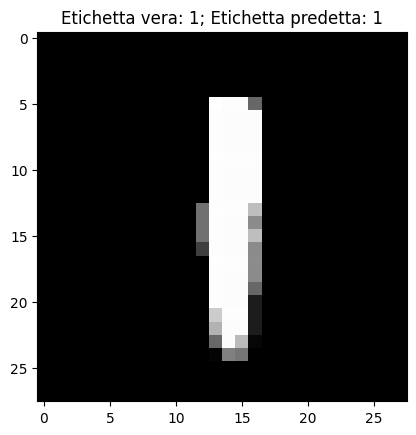

In [15]:
ID = 345 # indice nel test_set dell’immagine da analizzare
img = x_test[ID]
label = y_test[ID]
img = np.reshape(img, (-1,img_rows,img_cols,img_channels))
pred = lenet.predict(img)
print('vettore delle probabilità predette:', pred)

plt.figure()
plt.imshow(img[0,:,:,0], cmap='gray', clim=[0,1])
plt.title('Etichetta vera: %d; Etichetta predetta: %d' %(np.argmax(label),
                                                         np.argmax(pred)))
plt.show()


Valutiamo infine accuracy e loss della rete

In [ ]:
test_loss, test_accuracy = lenet.evaluate(x_test, y_test, verbose=True)
print('Test loss:', test_loss)
print('Test accuracy:', test_accuracy)


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9633 - loss: 0.1201
Test loss: 0.10508540272712708
Test accuracy: 0.9678999781608582
